# Leak detection

**Question:** which QUBO gives sensor placements that detect more leaks?

We compare the best placement of each QUBO (from Gurobi) on noisy networks that neither QUBO has seen.
A leak counts as detected if a sensor notices it within 30 minutes.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repo root
sys.path.append(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from src.qubo import (load_network, junction_demand, build_Q_topological, build_Q_leak,
                      energy, to_bits, cutoff)
from src.simulate_leaks import load_leak_table
from src.solvers import solve_max_detection
from src.utils import load_all_solutions, plot_network

networks = ["Net1", "Net2", "Net3"]
noise_seeds = [0, 1, 2, 3, 4]
rng = np.random.default_rng(0)

# the gurobi placements: the true best of each qubo
sol = load_all_solutions()
sol = sol[sol.solver == "gurobi"]


def detected_matrix(table):
    """S[i, j] = 1 if a sensor at junction j detects leak i within the cutoff."""
    return (table <= cutoff).values.astype(int)


def detection(S, x):
    """percent of leaks detected by the placement x (0s and 1s)."""
    return 100 * (S @ np.array(x) > 0).mean()


def random_placement(n, k):
    x = np.zeros(n, dtype=int)
    x[rng.choice(n, k, replace=False)] = 1
    return x

## 1. How many leaks does each placement detect?

Four placements for every network and every k:
- **random**: average of 200 random placements
- **topological**: best placement of the topological QUBO
- **leak**: best placement of the leak QUBO
- **best possible**: the most leaks any k sensors can detect

In [2]:
rows = []
for network in networks:
    clean = load_leak_table(network)
    nodes = list(clean.columns)
    tables = {"clean": clean}
    for seed in noise_seeds:
        tables[f"noisy {seed}"] = load_leak_table(network, noisy=True, seed=seed)

    for name, table in tables.items():
        S = detected_matrix(table)
        for k in sorted(sol[sol.network == network].k.unique()):
            result = {"random": np.mean([detection(S, random_placement(len(nodes), k)) for _ in range(200)]),
                      "best possible": 100 * solve_max_detection(S, k)[1] / len(S)}
            for qubo in ["topological", "leak"]:
                sensors = sol[(sol.network == network) & (sol.formulation == qubo) & (sol.k == k)].sensors.iloc[0]
                result[qubo] = detection(S, to_bits(sensors, nodes))
            for method, value in result.items():
                rows.append({"network": network, "k": k, "table": name, "method": method, "detection": value})

scores = pd.DataFrame(rows)
noisy = scores[scores.table != "clean"]

Restricted license - for non-production use only - expires 2028-11-29


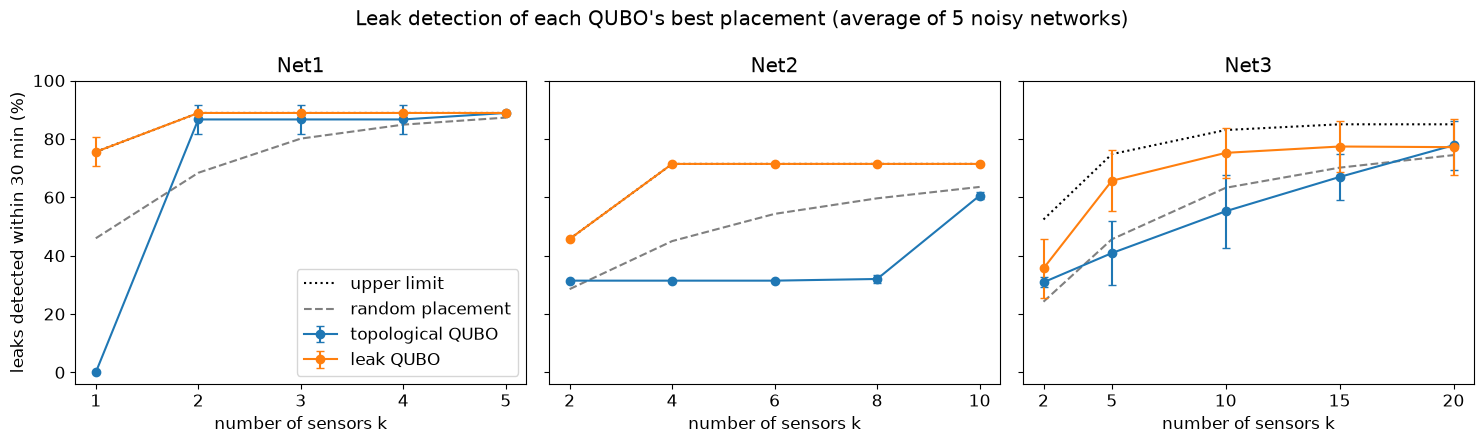

In [15]:
plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, network in zip(axes, networks):
    mean = noisy[noisy.network == network].groupby(["method", "k"])["detection"].mean()
    std = noisy[noisy.network == network].groupby(["method", "k"])["detection"].std()
    ks = mean["leak"].index

    # reference lines, thin and in the background
    ax.plot(ks, mean["best possible"], color="black", linestyle=":", label="upper limit")
    ax.plot(ks, mean["random"], color="gray", linestyle="--", label="random placement")

    # the two qubos, with the spread over the 5 noisy networks
    ax.errorbar(ks, mean["topological"], yerr=std["topological"], marker="o", capsize=3, color="tab:blue", label="topological QUBO")
    ax.errorbar(ks, mean["leak"], yerr=std["leak"], marker="o", capsize=3, color="tab:orange", label="leak QUBO")

    ax.set_title(network)
    ax.set_xlabel("number of sensors k")
    ax.set_xticks(ks)
    ax.set_ylim(-4, 100)
axes[0].set_ylabel("leaks detected within 30 min (%)")
axes[0].legend(loc="lower right")
fig.suptitle("Leak detection of each QUBO's best placement (average of 5 noisy networks)")
plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/leak_detection.png", dpi=200)

In [12]:
noisy.groupby(["network", "k", "method"])["detection"].mean().unstack()[["random", "topological", "leak", "best possible"]].round(0)

method      random  topological  leak  best possible
network k                                           
Net1    1     46.0          0.0  76.0           76.0
        2     68.0         87.0  89.0           89.0
        3     80.0         87.0  89.0           89.0
        4     85.0         87.0  89.0           89.0
        5     87.0         89.0  89.0           89.0
Net2    2     29.0         31.0  46.0           46.0
        4     45.0         31.0  71.0           71.0
        6     54.0         31.0  71.0           71.0
        8     60.0         32.0  71.0           71.0
        10    64.0         61.0  71.0           71.0
Net3    2     24.0         31.0  36.0           52.0
        5     46.0         41.0  66.0           75.0
        10    63.0         55.0  75.0           83.0
        15    70.0         67.0  77.0           85.0
        20    74.0         78.0  77.0           85.0

## 2. Is it different on the clean network?

The leak QUBO was built from the clean network, so the clean score is the easier test.

In [5]:
both = scores.assign(table=np.where(scores.table == "clean", "clean", "noisy"))
both.groupby(["network", "method", "table"])["detection"].mean().unstack().loc[networks].round(0)

table                  clean  noisy
network method                     
Net1    best possible   84.0   86.0
        leak            84.0   86.0
        random          69.0   73.0
        topological     64.0   70.0
Net2    best possible   62.0   66.0
        leak            61.0   66.0
        random          46.0   50.0
        topological     37.0   37.0
Net3    best possible   79.0   76.0
        leak            72.0   66.0
        random          57.0   56.0
        topological     57.0   54.0

## 3. Does a lower energy mean more leaks detected?

300 random placements per problem. For each one we compute its energy in both QUBOs and how many leaks it detects.
A negative correlation means lower energy goes with better detection.

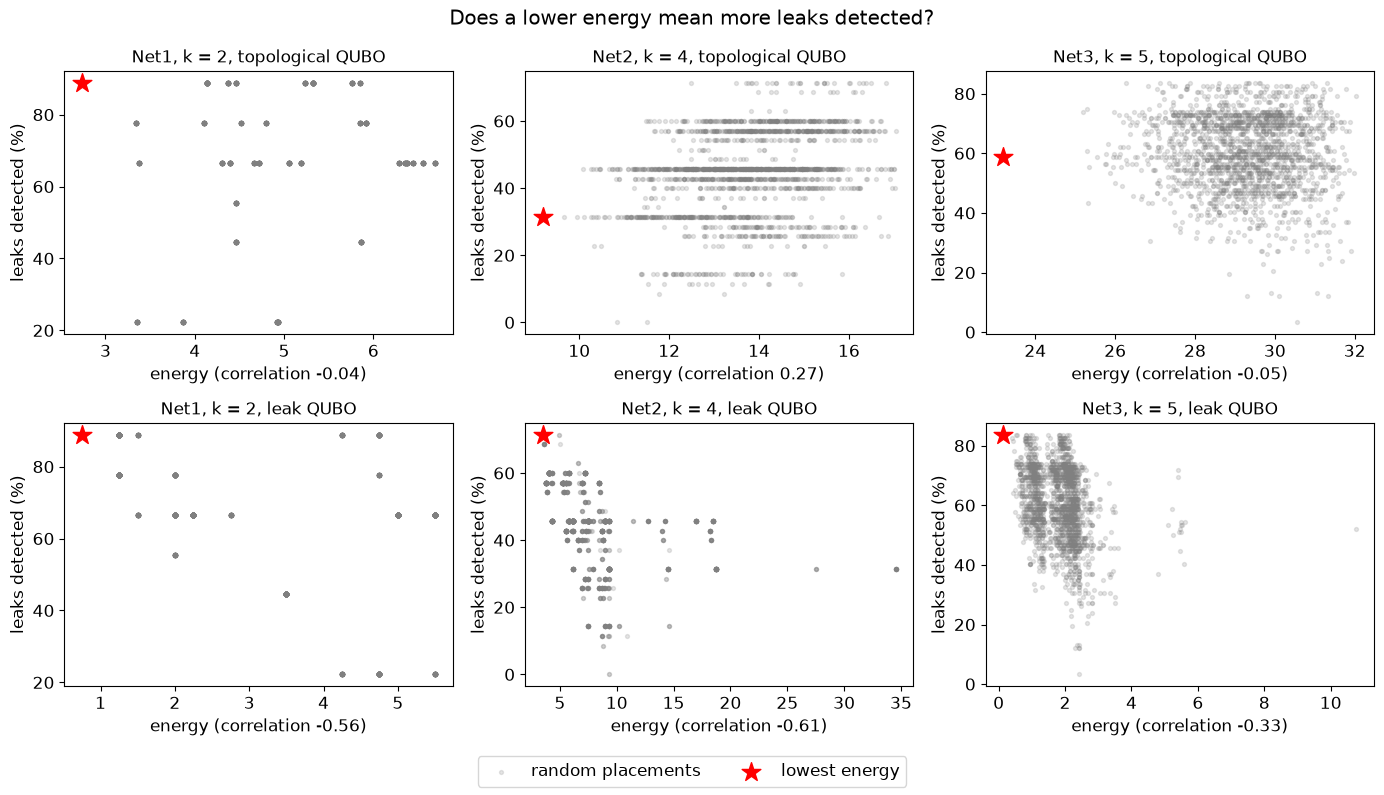

In [14]:
problems = [("Net1", 2), ("Net2", 4), ("Net3", 5)]
builders = {"topological": build_Q_topological, "leak": build_Q_leak}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, (network, k) in enumerate(problems):
    nodes = list(load_leak_table(network).columns)
    S = detected_matrix(load_leak_table(network, noisy=True))
    placements = [random_placement(len(nodes), k) for _ in range(2000)]
    detections = [detection(S, x) for x in placements]
    for row, (qubo, build) in enumerate(builders.items()):
        Q0, const0, _ = build(network, k, penalty=0)
        energies = [energy(Q0, const0, x) for x in placements]
        rho = spearmanr(energies, detections)[0]

        # the qubo's own best placement
        best = sol[(sol.network == network) & (sol.formulation == qubo) & (sol.k == k)].iloc[0]
        ax = axes[row, col]
        ax.scatter(energies, detections, s=8, alpha=0.2, color="gray", label="random placements")
        ax.scatter(best.energy, detection(S, to_bits(best.sensors, nodes)), s=200, marker="*", color="red", label="lowest energy")
        ax.set_title(f"{network}, k = {k}, {qubo} QUBO", fontsize=12)
        ax.set_xlabel(f"energy (correlation {rho:.2f})")
        ax.set_ylabel("leaks detected (%)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle("Does a lower energy mean more leaks detected?")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig("results/figures/energy_vs_detection.png", dpi=200)

## 4. Where does each QUBO put the sensors?

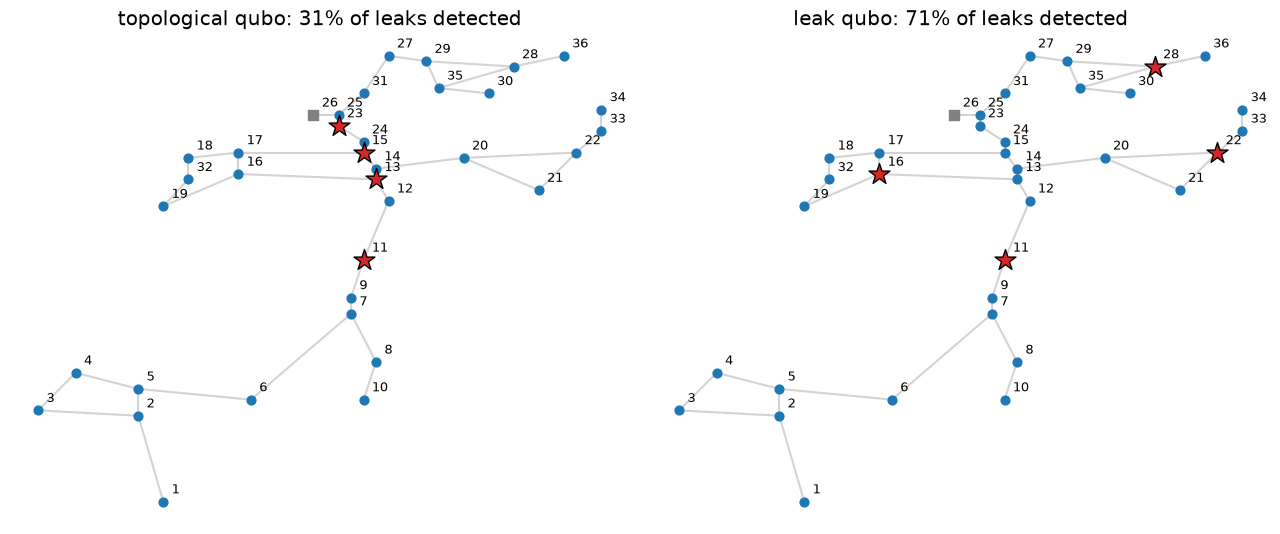

In [8]:
network, k = "Net2", 4
nodes = list(load_leak_table(network).columns)
S = detected_matrix(load_leak_table(network, noisy=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, qubo in zip(axes, ["topological", "leak"]):
    sensors = sol[(sol.network == network) & (sol.formulation == qubo) & (sol.k == k)].sensors.iloc[0]
    score = detection(S, to_bits(sensors, nodes))
    plot_network(network, sensors, ax=ax, title=f"{qubo} qubo: {score:.0f}% of leaks detected")
plt.tight_layout()
plt.savefig("results/figures/sensor_map_Net2.png", dpi=200)

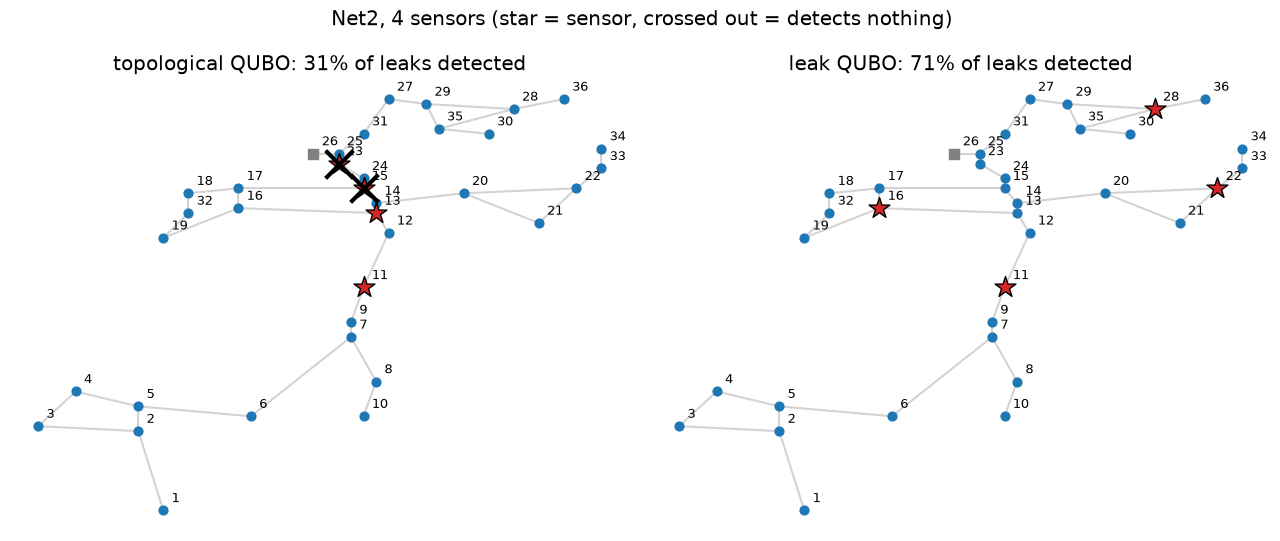

In [13]:
network, k = "Net2", 4
wn = load_network(network)
nodes = list(load_leak_table(network).columns)
S = detected_matrix(load_leak_table(network, noisy=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, qubo in zip(axes, ["topological", "leak"]):
    sensors = sol[(sol.network == network) & (sol.formulation == qubo) & (sol.k == k)].sensors.iloc[0]
    score = detection(S, to_bits(sensors, nodes))
    plot_network(network, sensors, ax=ax, title=f"{qubo} QUBO: {score:.0f}% of leaks detected")

    # cross out the sensors that detect no leak at all
    for s in sensors:
        if S[:, nodes.index(s)].sum() == 0:
            x, y = wn.get_node(s).coordinates
            ax.scatter(x, y, s=400, marker="x", color="black", linewidths=3, zorder=5)
fig.suptitle(f"{network}, {k} sensors (star = sensor, crossed out = detects nothing)")
plt.tight_layout()
plt.savefig("results/figures/sensor_map_Net2.png", dpi=200)

## Conclusion

- **The leak QUBO detects more leaks** than the topological QUBO, most clearly with few sensors.
- **The topological QUBO is about as good as random placement.** It puts sensors on the main pipe near the tank, where the pressure hardly changes.
- **With many sensors the difference disappears,** because any placement covers the network.
- **Low energy is a good sign only for the leak QUBO.** For the topological QUBO, energy says nothing about leak detection.

**Limits:** 5 noisy networks, and a leak counts as detected only within 30 minutes.